In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd


SUBJECT = "D0007"

TEST_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test"
)

OLD_PROFILE_DIR = (
    TEST_ROOT
    / "existing_pipeline"
    / "output"
    / SUBJECT
    / "adc"
    / "adc_cols_by_column"
)

NEW_PROFILE_DIR = (
    TEST_ROOT
    / "new_pipeline"
    / SUBJECT
    / "profiles"
)

OUTPUT_DIR = (
    TEST_ROOT
    / "comparison"
    / "end_to_end"
    / SUBJECT
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


print("Subject:", SUBJECT)
print("Old profiles:", OLD_PROFILE_DIR)
print("New profiles:", NEW_PROFILE_DIR)
print("Output:", OUTPUT_DIR)

Subject: D0007
Old profiles: /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/adc/adc_cols_by_column
New profiles: /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/profiles
Output: /mnt/newStor/paros/paros_WORK/xintong/test/comparison/end_to_end/D0007


In [ ]:
old_files = sorted(
    OLD_PROFILE_DIR.glob(
        f"{SUBJECT}_*_cols_adc.csv"
    )
)

new_files = sorted(
    NEW_PROFILE_DIR.glob(
        f"{SUBJECT}_*_md.csv"
    )
)

print("Old regions:", len(old_files))
print("New regions:", len(new_files))
def load_profile_csv(path):
    df = pd.read_csv(path)

    values = (
        df.select_dtypes(
            include=[np.number]
        )
        .to_numpy()
    )

    if values.shape[1] > 21:
        values = values[:, -21:]

    return values

Old regions: 68
New regions: 68


# Regional comparison

In [57]:
rows = []

all_old = []
all_new = []


for old_path in old_files:

    region_key = (
        old_path.stem
        .replace(f"{SUBJECT}_", "")
        .replace("_cols_adc", "")
    )

    new_path = (
        NEW_PROFILE_DIR
        / f"{SUBJECT}_{region_key}_md.csv"
    )

    if not new_path.exists():
        print("Missing:", new_path.name)
        continue

    old_values = load_profile_csv(
        old_path
    )

    new_values = load_profile_csv(
        new_path
    )

    old_profile = np.mean(
        old_values,
        axis=0,
    )

    new_profile = np.mean(
        new_values,
        axis=0,
    )

    difference = (
        new_profile
        - old_profile
    )

    rows.append({
        "region": region_key,
        "old_n_trajectories":
            old_values.shape[0],
        "new_n_trajectories":
            new_values.shape[0],
        "correlation":
            np.corrcoef(
                old_profile,
                new_profile,
            )[0, 1],
        "mae":
            np.mean(
                np.abs(difference)
            ),
        "rmse":
            np.sqrt(
                np.mean(
                    difference ** 2
                )
            ),
        "mean_difference":
            np.mean(difference),
    })

    all_old.extend(old_profile)
    all_new.extend(new_profile)


regional_comparison_df = pd.DataFrame(
    rows
)

display(regional_comparison_df)

,region,old_n_trajectories,new_n_trajectories,correlation,mae,rmse,mean_difference
0,lh_bankssts,1200,1200,0.999923,0.000002,0.000003,-7.355514e-07
1,lh_caudalanteriorcingulate,799,819,0.999302,0.000005,0.000006,1.113391e-06
2,lh_caudalmiddlefrontal,3179,3134,0.999770,0.000011,0.000013,1.077506e-05
3,lh_cuneus,2377,2291,0.999999,0.000015,0.000017,1.472132e-05
4,lh_entorhinal,568,663,0.997787,0.000020,0.000023,1.471448e-05
...,...,...,...,...,...,...,...
63,rh_superiorparietal,7324,7460,0.999935,0.000011,0.000012,1.054235e-05
64,rh_superiortemporal,4693,4823,0.999894,0.000009,0.000014,5.030415e-06
65,rh_supramarginal,5241,5196,0.999895,0.000011,0.000012,1.095912e-05
66,rh_temporalpole,595,619,0.996866,0.000057,0.000063,5.436612e-05


In [58]:
all_old = np.asarray(all_old)
all_new = np.asarray(all_new)

difference = (
    all_new
    - all_old
)

overall_comparison_df = pd.DataFrame([
    {
        "n_regions":
            len(regional_comparison_df),

        "correlation":
            np.corrcoef(
                all_old,
                all_new,
            )[0, 1],

        "mae":
            np.mean(
                np.abs(difference)
            ),

        "rmse":
            np.sqrt(
                np.mean(
                    difference ** 2
                )
            ),

        "mean_difference":
            np.mean(difference),
    }
])

display(
    overall_comparison_df
)

,n_regions,correlation,mae,rmse,mean_difference
0,68,0.995908,0.000013,0.000021,0.000007


In [59]:
all_old = np.asarray(all_old)
all_new = np.asarray(all_new)

difference = all_new - all_old

overall_comparison_df = pd.DataFrame([
    {
        "n_regions": len(regional_comparison_df),
        "correlation": np.corrcoef(
            all_old,
            all_new,
        )[0, 1],
        "mae": np.mean(
            np.abs(difference)
        ),
        "rmse": np.sqrt(
            np.mean(difference ** 2)
        ),
        "mean_difference": np.mean(
            difference
        ),
    }
])

display(overall_comparison_df)
largest_difference_df = (
    regional_comparison_df
    .sort_values(
        "mae",
        ascending=False,
    )
    .reset_index(drop=True)
)

display(
    largest_difference_df.head(20)
)
regional_comparison_df.to_csv(
    OUTPUT_DIR
    / "regional_profile_comparison.csv",
    index=False,
)

overall_comparison_df.to_csv(
    OUTPUT_DIR
    / "overall_profile_comparison.csv",
    index=False,
)

print("Saved to:", OUTPUT_DIR)

,n_regions,correlation,mae,rmse,mean_difference
0,68,0.995908,0.000013,0.000021,0.000007


,region,old_n_trajectories,new_n_trajectories,correlation,mae,rmse,mean_difference
0,rh_temporalpole,595,619,0.996866,0.000057,0.000063,0.000054
1,rh_entorhinal,546,660,0.997667,0.000056,0.000062,0.000053
2,rh_lateraloccipital,6612,6749,0.999280,0.000053,0.000075,-0.000053
3,rh_pericalcarine,2372,2154,0.999328,0.000039,0.000040,0.000039
4,lh_insula,2907,3068,0.999213,0.000028,0.000031,0.000028
5,rh_insula,3029,3228,0.999810,0.000028,0.000028,0.000028
6,rh_fusiform,2827,3128,0.996443,0.000026,0.000031,0.000018
7,lh_medialorbitofrontal,2664,2753,0.999858,0.000024,0.000026,0.000024
8,rh_inferiortemporal,2900,3487,0.999901,0.000023,0.000036,-0.000020
9,rh_postcentral,6091,6048,0.999817,0.000022,0.000023,0.000022


Saved to: /mnt/newStor/paros/paros_WORK/xintong/test/comparison/end_to_end/D0007


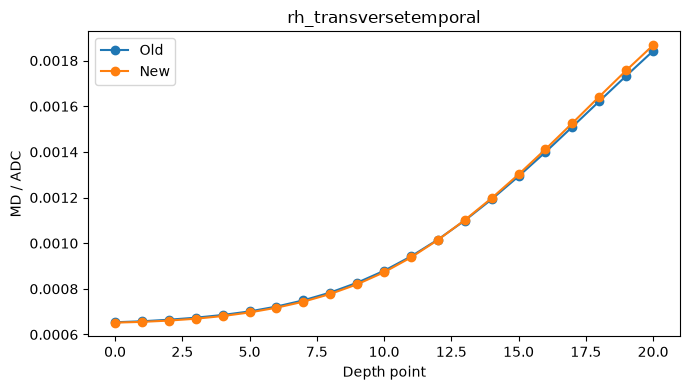

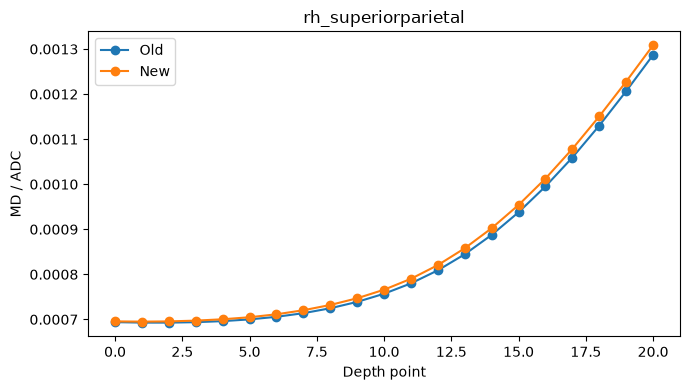

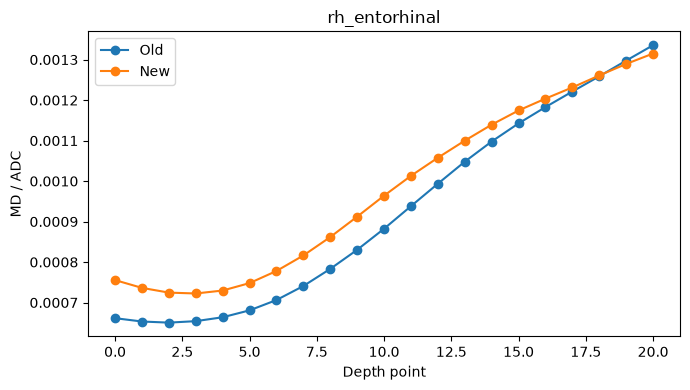

In [60]:
import matplotlib.pyplot as plt


def compare_region(region_key):
    old_path = (
        OLD_PROFILE_DIR
        / f"{SUBJECT}_{region_key}_cols_adc.csv"
    )

    new_path = (
        NEW_PROFILE_DIR
        / f"{SUBJECT}_{region_key}_md.csv"
    )

    old_values = load_profile_csv(old_path)
    new_values = load_profile_csv(new_path)

    old_profile = np.mean(old_values, axis=0)
    new_profile = np.mean(new_values, axis=0)

    plt.figure(figsize=(7, 4))

    plt.plot(
        range(21),
        old_profile,
        marker="o",
        label="Old",
    )

    plt.plot(
        range(21),
        new_profile,
        marker="o",
        label="New",
    )

    plt.xlabel("Depth point")
    plt.ylabel("MD / ADC")
    plt.title(region_key)
    plt.legend()
    plt.tight_layout()
    plt.show()


compare_region("rh_transversetemporal")
compare_region("rh_superiorparietal")
compare_region("rh_entorhinal")

In [61]:
from pathlib import Path
from scipy.io import loadmat


OLD_COLUMN_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/columns"
)

NEW_TRAJECTORY_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/trajectories"
)

files_to_check = {
    "OLD_LH": OLD_COLUMN_DIR / "D0007_column_lh_dwi.mat",
    "OLD_RH": OLD_COLUMN_DIR / "D0007_column_rh_dwi.mat",
    "NEW_LH": NEW_TRAJECTORY_DIR / "D0007_trajectory_lh_dwi.mat",
    "NEW_RH": NEW_TRAJECTORY_DIR / "D0007_trajectory_rh_dwi.mat",
}

for name, path in files_to_check.items():
    data = loadmat(path)

    print()
    print(name)
    print(path)

    for key, value in data.items():
        if key.startswith("__"):
            continue

        print(
            f"  {key}: "
            f"shape={getattr(value, 'shape', None)}, "
            f"dtype={getattr(value, 'dtype', None)}"
        )


OLD_LH
/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/columns/D0007_column_lh_dwi.mat
  lh_cp_dwi: shape=(4, 2497362), dtype=float64

OLD_RH
/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/columns/D0007_column_rh_dwi.mat
  rh_cp_dwi: shape=(4, 2494107), dtype=float64

NEW_LH
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/trajectories/D0007_trajectory_lh_dwi.mat
  lh_trajectory_dwi: shape=(4, 2525271), dtype=float64

NEW_RH
/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/trajectories/D0007_trajectory_rh_dwi.mat
  rh_trajectory_dwi: shape=(4, 2513385), dtype=float64


In [62]:
from pathlib import Path
from scipy.io import loadmat


OLD_REGION_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/columns/label_coord_1mm"
)

NEW_REGION_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/regions"
)

region = "rh_superiorparietal"

old_path = OLD_REGION_DIR / f"{region}.mat"
new_path = NEW_REGION_DIR / f"{region}.mat"

for label, path in [
    ("OLD", old_path),
    ("NEW", new_path),
]:
    data = loadmat(path)

    print()
    print(label, path)

    for key, value in data.items():
        if key.startswith("__"):
            continue

        print(
            f"{key}: "
            f"shape={value.shape}, "
            f"dtype={value.dtype}"
        )


OLD /mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/D0007/columns/label_coord_1mm/rh_superiorparietal.mat
rh_cp_dwi: shape=(4, 153825), dtype=float64

NEW /mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/regions/rh_superiorparietal.mat
rh_trajectory_dwi: shape=(4, 156681), dtype=float64


In [63]:
import numpy as np
import pandas as pd
from scipy.io import loadmat


def load_region_coordinates(path):
    data = loadmat(path)

    keys = [
        key for key in data.keys()
        if not key.startswith("__")
    ]

    if len(keys) != 1:
        raise ValueError(
            f"Expected one data variable in {path}, found: {keys}"
        )

    coords = np.asarray(data[keys[0]])

    if coords.shape[0] != 4:
        raise ValueError(
            f"Expected shape (4, N), got {coords.shape}"
        )

    n_points = coords.shape[1]

    if n_points % 21 != 0:
        raise ValueError(
            f"Number of points is not divisible by 21: {n_points}"
        )

    # Remove homogeneous coordinate and reshape:
    # (4, N*21) -> (N, 21, 3)
    coords = coords[:3, :].T
    coords = coords.reshape(-1, 21, 3)

    return coords


rows = []

old_files = sorted(OLD_REGION_DIR.glob("*.mat"))

for old_path in old_files:
    region = old_path.stem
    new_path = NEW_REGION_DIR / f"{region}.mat"

    if not new_path.exists():
        continue

    old_coords = load_region_coordinates(old_path)
    new_coords = load_region_coordinates(new_path)

    # Mean sampling coordinate at each cortical depth
    old_mean = np.mean(old_coords, axis=0)
    new_mean = np.mean(new_coords, axis=0)

    # Euclidean OLD-NEW distance at each depth
    depth_distance = np.linalg.norm(
        new_mean - old_mean,
        axis=1,
    )

    rows.append({
        "region": region,
        "old_n_trajectories": old_coords.shape[0],
        "new_n_trajectories": new_coords.shape[0],
        "mean_spatial_distance_vox": np.mean(depth_distance),
        "max_spatial_distance_vox": np.max(depth_distance),
        "white_distance_vox": depth_distance[0],
        "mid_distance_vox": depth_distance[10],
        "pial_distance_vox": depth_distance[20],
    })


geometry_df = pd.DataFrame(rows)

geometry_df = geometry_df.sort_values(
    "mean_spatial_distance_vox",
    ascending=False,
).reset_index(drop=True)

geometry_df

,region,old_n_trajectories,new_n_trajectories,mean_spatial_distance_vox,max_spatial_distance_vox,white_distance_vox,mid_distance_vox,pial_distance_vox
0,rh_inferiortemporal,2901,3488,3.465128,3.581264,3.349788,3.464898,3.581264
1,lh_temporalpole,630,622,3.110399,3.236370,3.009461,3.103145,3.236370
2,rh_temporalpole,596,620,2.471297,2.604975,2.350519,2.467564,2.604975
3,rh_cuneus,2546,2333,1.940576,1.992968,1.888724,1.940419,1.992968
4,rh_pericalcarine,2373,2155,1.687677,1.765228,1.610632,1.687531,1.765228
...,...,...,...,...,...,...,...,...
63,lh_superiorparietal,8090,8195,0.153059,0.155515,0.155515,0.152948,0.150986
64,lh_postcentral,5892,5808,0.152325,0.162986,0.141815,0.152281,0.162986
65,lh_parstriangularis,1529,1610,0.132894,0.154041,0.154041,0.132581,0.112837
66,rh_precuneus,5396,5417,0.120788,0.123495,0.118140,0.120771,0.123495


In [64]:
combined_df = regional_comparison_df.merge(
    geometry_df,
    on="region",
    suffixes=("_profile", "_geometry"),
)

combined_df = combined_df.sort_values(
    "mae",
    ascending=False,
).reset_index(drop=True)

combined_df[
    [
        "region",
        "mae",
        "correlation",
        "mean_spatial_distance_vox",
        "max_spatial_distance_vox",
        "white_distance_vox",
        "mid_distance_vox",
        "pial_distance_vox",
    ]
].head(20)

,region,mae,correlation,mean_spatial_distance_vox,max_spatial_distance_vox,white_distance_vox,mid_distance_vox,pial_distance_vox
0,rh_temporalpole,0.000057,0.996866,2.471297,2.604975,2.350519,2.467564,2.604975
1,rh_entorhinal,0.000056,0.997667,1.483222,1.560156,1.560156,1.480834,1.414536
2,rh_lateraloccipital,0.000053,0.999280,0.855669,0.883141,0.828370,0.855619,0.883141
3,rh_pericalcarine,0.000039,0.999328,1.687677,1.765228,1.610632,1.687531,1.765228
4,lh_insula,0.000028,0.999213,0.935719,0.972158,0.899381,0.935690,0.972158
5,rh_insula,0.000028,0.999810,1.301676,1.309865,1.309865,1.301068,1.295587
6,rh_fusiform,0.000026,0.996443,0.856533,0.887859,0.887859,0.856018,0.826988
7,lh_medialorbitofrontal,0.000024,0.999858,0.474696,0.480309,0.480309,0.474014,0.471437
8,rh_inferiortemporal,0.000023,0.999901,3.465128,3.581264,3.349788,3.464898,3.581264
9,rh_postcentral,0.000022,0.999817,0.188545,0.191212,0.186541,0.188353,0.191212


In [65]:
print(
    "Correlation between spatial difference and MD MAE:"
)

print(
    combined_df[
        [
            "mean_spatial_distance_vox",
            "mae",
        ]
    ].corr().iloc[0, 1]
)

Correlation between spatial difference and MD MAE:
0.42602844553403113


In [66]:
from scipy.spatial import cKDTree


def symmetric_nearest_neighbor_distance(old_points, new_points):
    old_tree = cKDTree(old_points)
    new_tree = cKDTree(new_points)

    old_to_new, _ = new_tree.query(old_points, k=1)
    new_to_old, _ = old_tree.query(new_points, k=1)

    return (
        np.mean(old_to_new) + np.mean(new_to_old)
    ) / 2


rows = []

for old_path in sorted(OLD_REGION_DIR.glob("*.mat")):
    region = old_path.stem
    new_path = NEW_REGION_DIR / f"{region}.mat"

    if not new_path.exists():
        continue

    old_coords = load_region_coordinates(old_path)
    new_coords = load_region_coordinates(new_path)

    depth_distances = []

    for depth in range(21):
        old_points = old_coords[:, depth, :]
        new_points = new_coords[:, depth, :]

        distance = symmetric_nearest_neighbor_distance(
            old_points,
            new_points,
        )

        depth_distances.append(distance)

    rows.append({
        "region": region,
        "mean_nn_distance_vox": np.mean(depth_distances),
        "max_nn_distance_vox": np.max(depth_distances),
        "white_nn_distance_vox": depth_distances[0],
        "mid_nn_distance_vox": depth_distances[10],
        "pial_nn_distance_vox": depth_distances[20],
    })


distribution_geometry_df = pd.DataFrame(rows)

distribution_geometry_df = distribution_geometry_df.sort_values(
    "mean_nn_distance_vox",
    ascending=False,
).reset_index(drop=True)

distribution_geometry_df.head(20)

,region,mean_nn_distance_vox,max_nn_distance_vox,white_nn_distance_vox,mid_nn_distance_vox,pial_nn_distance_vox
0,lh_temporalpole,0.802735,0.918639,0.702814,0.800519,0.918639
1,rh_temporalpole,0.698194,0.737950,0.670924,0.695842,0.737950
2,rh_inferiortemporal,0.673117,0.757884,0.579231,0.675467,0.757884
3,rh_entorhinal,0.658770,0.784860,0.784860,0.642654,0.598169
4,lh_entorhinal,0.635577,0.744789,0.744789,0.621169,0.584466
5,rh_pericalcarine,0.592681,0.620439,0.569398,0.590706,0.620439
6,lh_inferiortemporal,0.552792,0.601651,0.491737,0.556437,0.601651
7,lh_fusiform,0.476582,0.496275,0.454975,0.477875,0.496275
8,rh_middletemporal,0.464840,0.512837,0.414526,0.465470,0.512837
9,lh_insula,0.464221,0.521409,0.521409,0.457065,0.437624


In [67]:
distribution_combined_df = regional_comparison_df.merge(
    distribution_geometry_df,
    on="region",
)

print(
    "Correlation between point-cloud distance and MD MAE:",
    distribution_combined_df[
        ["mean_nn_distance_vox", "mae"]
    ].corr().iloc[0, 1]
)

Correlation between point-cloud distance and MD MAE: 0.5542846086547493


In [68]:
from pathlib import Path

OLD_ADC = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/input/"
    "D0007/D0007_adc.nii.gz"
)

NEW_ADC = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_adc.nii.gz"
)

NEW_REGION_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/regions"
)

In [69]:
import numpy as np
import pandas as pd
import nibabel as nib

from scipy.io import loadmat
from scipy.ndimage import map_coordinates


def load_region_coordinates(path):
    data = loadmat(path)

    keys = [
        key for key in data.keys()
        if not key.startswith("__")
    ]

    if len(keys) != 1:
        raise ValueError(
            f"Expected one data variable in {path}, found: {keys}"
        )

    coords = np.asarray(data[keys[0]])

    if coords.shape[0] != 4:
        raise ValueError(
            f"Expected shape (4, N), got {coords.shape}"
        )

    if coords.shape[1] % 21 != 0:
        raise ValueError(
            f"Number of points is not divisible by 21: "
            f"{coords.shape[1]}"
        )

    coords = coords[:3, :].T
    coords = coords.reshape(-1, 21, 3)

    return coords


def sample_volume(volume, coords):
    flat_coords = coords.reshape(-1, 3)

    sample_coords = [
        flat_coords[:, 0],
        flat_coords[:, 1],
        flat_coords[:, 2],
    ]

    sampled = map_coordinates(
        volume,
        sample_coords,
        order=1,
        mode="nearest",
    )

    return sampled.reshape(-1, 21)

In [70]:
old_img = nib.load(OLD_ADC)
new_img = nib.load(NEW_ADC)

old_volume = old_img.get_fdata()
new_volume = new_img.get_fdata()

print("OLD shape:", old_volume.shape)
print("NEW shape:", new_volume.shape)

print(
    "Affine equal:",
    np.allclose(old_img.affine, new_img.affine),
)

OLD shape: (164, 328, 122)
NEW shape: (164, 328, 122)
Affine equal: True


In [71]:
rows = []

for region_path in sorted(NEW_REGION_DIR.glob("*.mat")):
    region = region_path.stem

    coords = load_region_coordinates(region_path)

    old_sampled = sample_volume(
        old_volume,
        coords,
    )

    new_sampled = sample_volume(
        new_volume,
        coords,
    )

    old_profile = np.mean(old_sampled, axis=0)
    new_profile = np.mean(new_sampled, axis=0)

    correlation = np.corrcoef(
        old_profile,
        new_profile,
    )[0, 1]

    diff = new_profile - old_profile

    rows.append({
        "region": region,
        "n_trajectories": coords.shape[0],
        "correlation": correlation,
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
    })


same_coordinate_df = pd.DataFrame(rows)

same_coordinate_df

,region,n_trajectories,correlation,mae,rmse,mean_difference
0,lh_bankssts,1201,0.999995,1.977468e-07,2.426610e-07,-1.700760e-08
1,lh_caudalanteriorcingulate,820,0.999991,2.467747e-06,2.902462e-06,-1.872291e-06
2,lh_caudalmiddlefrontal,3135,0.999998,8.308072e-07,8.866217e-07,-8.072872e-07
3,lh_cuneus,2292,0.999970,1.649293e-06,1.818242e-06,-6.527163e-07
4,lh_entorhinal,664,0.999967,2.883940e-06,3.309127e-06,1.191799e-06
...,...,...,...,...,...,...
63,rh_superiorparietal,7461,1.000000,2.118138e-07,2.391979e-07,5.505766e-08
64,rh_superiortemporal,4824,0.999981,2.358691e-06,2.790082e-06,-4.410922e-08
65,rh_supramarginal,5197,0.999992,1.280380e-06,1.643862e-06,-1.722712e-07
66,rh_temporalpole,620,0.999994,3.798421e-06,3.982836e-06,-3.798421e-06


In [72]:
all_old = []
all_new = []

for region_path in sorted(NEW_REGION_DIR.glob("*.mat")):
    coords = load_region_coordinates(region_path)

    old_sampled = sample_volume(
        old_volume,
        coords,
    )

    new_sampled = sample_volume(
        new_volume,
        coords,
    )

    all_old.append(
        np.mean(old_sampled, axis=0)
    )

    all_new.append(
        np.mean(new_sampled, axis=0)
    )


all_old = np.concatenate(all_old)
all_new = np.concatenate(all_new)

diff = all_new - all_old

same_coordinate_overall = pd.DataFrame([
    {
        "n_regions": len(same_coordinate_df),
        "correlation": np.corrcoef(
            all_old,
            all_new,
        )[0, 1],
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
    }
])

same_coordinate_overall

,n_regions,correlation,mae,rmse,mean_difference
0,68,0.997645,0.000005,0.000015,9.729897e-07


In [73]:
rows = []

for old_path in sorted(OLD_REGION_DIR.glob("*.mat")):
    region = old_path.stem
    new_path = NEW_REGION_DIR / f"{region}.mat"

    if not new_path.exists():
        continue

    old_coords = load_region_coordinates(old_path)
    new_coords = load_region_coordinates(new_path)

    old_sampled = sample_volume(
        new_volume,
        old_coords,
    )

    new_sampled = sample_volume(
        new_volume,
        new_coords,
    )

    old_profile = np.mean(old_sampled, axis=0)
    new_profile = np.mean(new_sampled, axis=0)

    correlation = np.corrcoef(
        old_profile,
        new_profile,
    )[0, 1]

    diff = new_profile - old_profile

    rows.append({
        "region": region,
        "old_n_trajectories": old_coords.shape[0],
        "new_n_trajectories": new_coords.shape[0],
        "correlation": correlation,
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
    })


geometry_only_df = pd.DataFrame(rows)

geometry_only_df

,region,old_n_trajectories,new_n_trajectories,correlation,mae,rmse,mean_difference
0,lh_bankssts,1201,1201,0.999578,0.000004,0.000005,-0.000003
1,lh_caudalanteriorcingulate,800,820,0.999063,0.000015,0.000016,0.000005
2,lh_caudalmiddlefrontal,3180,3135,0.999440,0.000004,0.000005,0.000002
3,lh_cuneus,2378,2292,0.999648,0.000024,0.000024,0.000024
4,lh_entorhinal,569,664,0.999092,0.000029,0.000031,0.000010
...,...,...,...,...,...,...,...
63,rh_superiorparietal,7325,7461,0.999811,0.000012,0.000013,0.000012
64,rh_superiortemporal,4694,4824,0.999998,0.000007,0.000008,0.000005
65,rh_supramarginal,5242,5197,0.999871,0.000010,0.000011,0.000009
66,rh_temporalpole,596,620,0.997617,0.000077,0.000084,0.000075


In [74]:
all_old = []
all_new = []

for old_path in sorted(OLD_REGION_DIR.glob("*.mat")):
    region = old_path.stem
    new_path = NEW_REGION_DIR / f"{region}.mat"

    if not new_path.exists():
        continue

    old_coords = load_region_coordinates(old_path)
    new_coords = load_region_coordinates(new_path)

    old_sampled = sample_volume(
        new_volume,
        old_coords,
    )

    new_sampled = sample_volume(
        new_volume,
        new_coords,
    )

    all_old.append(
        np.mean(old_sampled, axis=0)
    )

    all_new.append(
        np.mean(new_sampled, axis=0)
    )


all_old = np.concatenate(all_old)
all_new = np.concatenate(all_new)

diff = all_new - all_old

geometry_only_overall = pd.DataFrame([
    {
        "n_regions": len(geometry_only_df),
        "correlation": np.corrcoef(
            all_old,
            all_new,
        )[0, 1],
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
    }
])

geometry_only_overall

,n_regions,correlation,mae,rmse,mean_difference
0,68,0.993687,0.000018,0.000026,0.000012


In [75]:
import numpy as np
import pandas as pd
import nibabel as nib

from pathlib import Path
from scipy.io import loadmat
from scipy.ndimage import map_coordinates


SUBJECT = "D0007"
DEPTH_SAMPLES = 21

TEST_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test"
)

OLD_ROOT = (
    TEST_ROOT
    / "existing_pipeline"
    / "output"
    / SUBJECT
)

NEW_ROOT = (
    TEST_ROOT
    / "new_pipeline"
    / SUBJECT
)

OLD_COLUMN_DIR = OLD_ROOT / "columns"

NEW_TRAJECTORY_DIR = (
    NEW_ROOT
    / "trajectories"
)

NEW_ADC = (
    NEW_ROOT
    / "diffusion"
    / f"{SUBJECT}_adc.nii.gz"
)

OLD_REG = (
    OLD_ROOT
    / "DWI2T1_dti.dat"
)

NEW_REG = (
    NEW_ROOT
    / "registration"
    / "DWI2T1_dti_masked.dat"
)


def load_transform_matrix(path):
    rows = []

    with open(path, "r") as f:
        for line in f:
            values = line.strip().split()

            if len(values) != 4:
                continue

            try:
                row = [
                    float(value)
                    for value in values
                ]
            except ValueError:
                continue

            rows.append(row)

    if len(rows) < 4:
        raise ValueError(
            f"Could not find 4x4 matrix in {path}"
        )

    return np.asarray(
        rows[:4],
        dtype=float,
    )


def vox2ras_tkreg(shape, voxel_size):
    nx, ny, nz = [
        float(value)
        for value in shape
    ]

    dx, dy, dz = [
        float(value)
        for value in voxel_size
    ]

    matrix = np.zeros(
        (4, 4),
        dtype=float,
    )

    matrix[0, 0] = -dx
    matrix[0, 3] = dx * nx / 2.0

    matrix[1, 2] = dz
    matrix[1, 3] = -dz * nz / 2.0

    matrix[2, 1] = -dy
    matrix[2, 3] = dy * ny / 2.0

    matrix[3, 3] = 1.0

    return matrix


def vox2ras_0to1(matrix):
    q = np.zeros(
        (4, 4),
        dtype=float,
    )

    q[:3, 3] = 1.0

    return np.linalg.inv(
        np.linalg.inv(matrix) + q
    )


def load_t1_trajectories(path):
    data = loadmat(path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    if len(keys) != 1:
        print(
            f"{path.name}: variables = {keys}"
        )

    key = keys[0]

    values = np.asarray(
        data[key],
        dtype=float,
    )

    # Common flattened format: 3 x (N*21)
    if (
        values.ndim == 2
        and values.shape[0] == 3
    ):
        points = values.T

    # Homogeneous format: 4 x (N*21)
    elif (
        values.ndim == 2
        and values.shape[0] == 4
    ):
        points = values[:3, :].T

    # Already transposed
    elif (
        values.ndim == 2
        and values.shape[1] in (3, 4)
    ):
        points = values[:, :3]

    # Already N x 21 x 3
    elif (
        values.ndim == 3
        and values.shape[-1] == 3
    ):
        return values

    else:
        raise ValueError(
            f"Unexpected shape in {path}: "
            f"{values.shape}"
        )

    if (
        points.shape[0]
        % DEPTH_SAMPLES
        != 0
    ):
        raise ValueError(
            f"{path}: point count "
            f"{points.shape[0]} "
            "is not divisible by 21"
        )

    return points.reshape(
        -1,
        DEPTH_SAMPLES,
        3,
    )


def transform_to_dwi(
    trajectories,
    transform,
    t_mov,
):
    points = trajectories.reshape(
        -1,
        3,
    )

    homogeneous = np.ones(
        (4, points.shape[0]),
        dtype=float,
    )

    homogeneous[:3, :] = points.T

    transformed = (
        np.linalg.inv(t_mov)
        @ transform
        @ homogeneous
    )

    return (
        transformed[:3, :]
        .T
        .reshape(
            -1,
            DEPTH_SAMPLES,
            3,
        )
    )


def sample_volume(
    volume,
    coords,
):
    # Coordinates are stored using 1-based
    # voxel indexing in this pipeline.
    sample_coords = (
        coords.reshape(-1, 3).T
        - 1.0
    )

    sampled = map_coordinates(
        volume,
        sample_coords,
        order=1,
        mode="nearest",
    )

    return sampled.reshape(
        -1,
        DEPTH_SAMPLES,
    )


def compare_profiles(
    profile_a,
    profile_b,
):
    profile_a = np.asarray(
        profile_a,
        dtype=float,
    )

    profile_b = np.asarray(
        profile_b,
        dtype=float,
    )

    diff = profile_b - profile_a

    return {
        "correlation": np.corrcoef(
            profile_a,
            profile_b,
        )[0, 1],
        "mae": np.mean(
            np.abs(diff)
        ),
        "rmse": np.sqrt(
            np.mean(diff ** 2)
        ),
        "mean_difference": np.mean(
            diff
        ),
    }


# Load NEW ADC.
new_adc_img = nib.load(
    str(NEW_ADC)
)

new_volume = (
    new_adc_img.get_fdata()
)

shape = (
    new_adc_img.shape[:3]
)

voxel_size = (
    new_adc_img
    .header
    .get_zooms()[:3]
)

t_mov = vox2ras_0to1(
    vox2ras_tkreg(
        shape,
        voxel_size,
    )
)

old_transform = (
    load_transform_matrix(
        OLD_REG
    )
)

new_transform = (
    load_transform_matrix(
        NEW_REG
    )
)


# Registration-only experiment
registration_old_profiles = []
registration_new_profiles = []

registration_rows = []

for hemi in ["lh", "rh"]:

    old_t1 = (
        load_t1_trajectories(
            OLD_COLUMN_DIR
            / f"{SUBJECT}_column_{hemi}.mat"
        )
    )

    coords_old_reg = (
        transform_to_dwi(
            old_t1,
            old_transform,
            t_mov,
        )
    )

    coords_new_reg = (
        transform_to_dwi(
            old_t1,
            new_transform,
            t_mov,
        )
    )

    sampled_old_reg = sample_volume(
        new_volume,
        coords_old_reg,
    )

    sampled_new_reg = sample_volume(
        new_volume,
        coords_new_reg,
    )

    profile_old_reg = np.mean(
        sampled_old_reg,
        axis=0,
    )

    profile_new_reg = np.mean(
        sampled_new_reg,
        axis=0,
    )

    metrics = compare_profiles(
        profile_old_reg,
        profile_new_reg,
    )

    registration_rows.append({
        "hemisphere": hemi,
        "n_trajectories":
            old_t1.shape[0],
        **metrics,
    })

    registration_old_profiles.append(
        profile_old_reg
    )

    registration_new_profiles.append(
        profile_new_reg
    )


registration_old_all = np.concatenate(
    registration_old_profiles
)

registration_new_all = np.concatenate(
    registration_new_profiles
)

registration_overall = {
    "experiment":
        "Registration only",
    **compare_profiles(
        registration_old_all,
        registration_new_all,
    ),
}


# T1 trajectory / FreeSurfer-only experiment
trajectory_old_profiles = []
trajectory_new_profiles = []

trajectory_rows = []

for hemi in ["lh", "rh"]:

    old_t1 = (
        load_t1_trajectories(
            OLD_COLUMN_DIR
            / f"{SUBJECT}_column_{hemi}.mat"
        )
    )

    new_t1 = (
        load_t1_trajectories(
            NEW_TRAJECTORY_DIR
            / f"{SUBJECT}_trajectory_{hemi}.mat"
        )
    )

    # Same registration for both.
    old_coords = (
        transform_to_dwi(
            old_t1,
            new_transform,
            t_mov,
        )
    )

    new_coords = (
        transform_to_dwi(
            new_t1,
            new_transform,
            t_mov,
        )
    )

    old_sampled = sample_volume(
        new_volume,
        old_coords,
    )

    new_sampled = sample_volume(
        new_volume,
        new_coords,
    )

    old_profile = np.mean(
        old_sampled,
        axis=0,
    )

    new_profile = np.mean(
        new_sampled,
        axis=0,
    )

    metrics = compare_profiles(
        old_profile,
        new_profile,
    )

    trajectory_rows.append({
        "hemisphere": hemi,
        "old_n_trajectories":
            old_t1.shape[0],
        "new_n_trajectories":
            new_t1.shape[0],
        **metrics,
    })

    trajectory_old_profiles.append(
        old_profile
    )

    trajectory_new_profiles.append(
        new_profile
    )


trajectory_old_all = np.concatenate(
    trajectory_old_profiles
)

trajectory_new_all = np.concatenate(
    trajectory_new_profiles
)

trajectory_overall = {
    "experiment":
        "T1 trajectory / FreeSurfer only",
    **compare_profiles(
        trajectory_old_all,
        trajectory_new_all,
    ),
}


# Previously measured results
previous_results = [
    {
        "experiment":
            "Full end-to-end",
        "correlation": 0.942154,
        "mae": 0.000059,
        "rmse": 0.000087,
        "mean_difference":
            0.000031,
    },
    {
        "experiment":
            "Image only",
        "correlation": 0.995122,
        "mae": 0.000007,
        "rmse": 0.000023,
        "mean_difference":
            -1.190009e-07,
    },
    {
        "experiment":
            "Full geometry",
        "correlation": 0.942715,
        "mae": 0.000055,
        "rmse": 0.000076,
        "mean_difference":
            0.000011,
    },
]


summary_df = pd.DataFrame(
    previous_results
    + [
        registration_overall,
        trajectory_overall,
    ]
)

full_mae = (
    summary_df.loc[
        summary_df["experiment"]
        == "Full end-to-end",
        "mae",
    ]
    .iloc[0]
)

summary_df[
    "mae_relative_to_end_to_end"
] = (
    summary_df["mae"]
    / full_mae
)

print("\nRegistration-only by hemisphere:")
display(
    pd.DataFrame(
        registration_rows
    )
)

print(
    "\nT1 trajectory / FreeSurfer-only "
    "by hemisphere:"
)
display(
    pd.DataFrame(
        trajectory_rows
    )
)

print("\nFinal comparison:")
display(summary_df)


Registration-only by hemisphere:


,hemisphere,n_trajectories,correlation,mae,rmse,mean_difference
0,lh,118922,0.999078,0.000034,0.000046,0.000025
1,rh,118767,0.997349,0.000037,0.000046,0.000034



T1 trajectory / FreeSurfer-only by hemisphere:


,hemisphere,old_n_trajectories,new_n_trajectories,correlation,mae,rmse,mean_difference
0,lh,118922,120251,1.000000,0.000003,0.000003,0.000003
1,rh,118767,119685,0.999999,0.000002,0.000002,0.000002



Final comparison:


,experiment,correlation,mae,rmse,mean_difference,mae_relative_to_end_to_end
0,Full end-to-end,0.942154,0.000059,0.000087,3.100000e-05,1.000000
1,Image only,0.995122,0.000007,0.000023,-1.190009e-07,0.118644
2,Full geometry,0.942715,0.000055,0.000076,1.100000e-05,0.932203
3,Registration only,0.997494,0.000035,0.000046,2.955022e-05,0.600673
4,T1 trajectory / FreeSurfer only,0.999993,0.000002,0.000002,2.269132e-06,0.038460


In [76]:
from pathlib import Path

import numpy as np
import pandas as pd
import nibabel as nib

from scipy.io import loadmat
from scipy.ndimage import map_coordinates


# Inputs
SUBJECT = "D0007"
N_DEPTH = 21

TEST_ROOT = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test"
)

OLD_ROOT = (
    TEST_ROOT
    / "existing_pipeline"
    / "output"
    / SUBJECT
)

NEW_ROOT = (
    TEST_ROOT
    / "new_pipeline"
    / SUBJECT
)

OLD_REGION_DIR = (
    OLD_ROOT
    / "columns"
    / "label_coord_1mm"
)

NEW_REGION_DIR = (
    NEW_ROOT
    / "regions"
)

NEW_ADC = (
    NEW_ROOT
    / "diffusion"
    / f"{SUBJECT}_adc.nii.gz"
)

OLD_REG = (
    OLD_ROOT
    / "DWI2T1_dti.dat"
)

NEW_REG = (
    NEW_ROOT
    / "registration"
    / "DWI2T1_dti_masked.dat"
)


# Load bbregister matrix
def load_transform_matrix(path):
    rows = []

    with open(path, "r") as file:
        for line in file:
            values = line.strip().split()

            if len(values) != 4:
                continue

            try:
                row = [
                    float(value)
                    for value in values
                ]
            except ValueError:
                continue

            rows.append(row)

    if len(rows) < 4:
        raise ValueError(
            f"Could not find 4x4 matrix in {path}"
        )

    return np.asarray(
        rows[:4],
        dtype=float,
    )


# Reproduce FreeSurfer tkregister voxel geometry
def vox2ras_tkreg(shape, voxel_size):
    nx, ny, nz = [
        float(value)
        for value in shape
    ]

    dx, dy, dz = [
        float(value)
        for value in voxel_size
    ]

    matrix = np.zeros(
        (4, 4),
        dtype=float,
    )

    matrix[0, 0] = -dx
    matrix[0, 3] = dx * nx / 2.0

    matrix[1, 2] = dz
    matrix[1, 3] = -dz * nz / 2.0

    matrix[2, 1] = -dy
    matrix[2, 3] = dy * ny / 2.0

    matrix[3, 3] = 1.0

    return matrix


def vox2ras_0to1(matrix):
    q = np.zeros(
        (4, 4),
        dtype=float,
    )

    q[:3, 3] = 1.0

    return np.linalg.inv(
        np.linalg.inv(matrix) + q
    )


# Load one region's DWI-space trajectory coordinates
def load_region_coordinates(path):
    data = loadmat(path)

    keys = [
        key
        for key in data.keys()
        if not key.startswith("__")
    ]

    coordinate_keys = [
        key
        for key in keys
        if (
            "dwi" in key.lower()
            or "coord" in key.lower()
        )
    ]

    if coordinate_keys:
        key = coordinate_keys[0]

    elif len(keys) == 1:
        key = keys[0]

    else:
        raise ValueError(
            f"Could not identify coordinate variable "
            f"in {path}: {keys}"
        )

    coords = np.asarray(
        data[key],
        dtype=float,
    )

    if coords.ndim != 2:
        raise ValueError(
            f"Unexpected shape in {path}: "
            f"{coords.shape}"
        )

    if coords.shape[0] in (3, 4):
        coords = coords[:3, :].T

    elif coords.shape[1] in (3, 4):
        coords = coords[:, :3]

    else:
        raise ValueError(
            f"Could not interpret coordinates "
            f"in {path}: {coords.shape}"
        )

    if coords.shape[0] % N_DEPTH != 0:
        raise ValueError(
            f"{path}: point count "
            f"{coords.shape[0]} "
            f"is not divisible by {N_DEPTH}"
        )

    return coords.reshape(
        -1,
        N_DEPTH,
        3,
    )


# Convert DWI voxel coordinates back to T1 tkregister coordinates
def dwi_to_t1(
    dwi_coords,
    transform,
    t_mov,
):
    points = dwi_coords.reshape(
        -1,
        3,
    )

    homogeneous = np.ones(
        (4, points.shape[0]),
        dtype=float,
    )

    homogeneous[:3, :] = points.T

    t1_points = (
        np.linalg.inv(transform)
        @ t_mov
        @ homogeneous
    )

    return (
        t1_points[:3, :]
        .T
        .reshape(
            -1,
            N_DEPTH,
            3,
        )
    )


# Transform T1 coordinates into DWI voxel coordinates
def t1_to_dwi(
    t1_coords,
    transform,
    t_mov,
):
    points = t1_coords.reshape(
        -1,
        3,
    )

    homogeneous = np.ones(
        (4, points.shape[0]),
        dtype=float,
    )

    homogeneous[:3, :] = points.T

    dwi_points = (
        np.linalg.inv(t_mov)
        @ transform
        @ homogeneous
    )

    return (
        dwi_points[:3, :]
        .T
        .reshape(
            -1,
            N_DEPTH,
            3,
        )
    )


# Sample ADC using the same 1-based voxel convention
def sample_volume(
    volume,
    coords,
):
    sample_coords = (
        coords.reshape(-1, 3).T
        - 1.0
    )

    sampled = map_coordinates(
        volume,
        sample_coords,
        order=1,
        mode="nearest",
    )

    return sampled.reshape(
        -1,
        N_DEPTH,
    )


def compare_profiles(
    old_profile,
    new_profile,
):
    old_profile = np.asarray(
        old_profile,
        dtype=float,
    )

    new_profile = np.asarray(
        new_profile,
        dtype=float,
    )

    diff = (
        new_profile
        - old_profile
    )

    return {
        "correlation": np.corrcoef(
            old_profile,
            new_profile,
        )[0, 1],

        "mae": np.mean(
            np.abs(diff)
        ),

        "rmse": np.sqrt(
            np.mean(diff ** 2)
        ),

        "mean_difference": np.mean(
            diff
        ),
    }


# Load NEW ADC and geometry
new_adc_img = nib.load(
    str(NEW_ADC)
)

new_volume = (
    new_adc_img.get_fdata()
)

shape = (
    new_adc_img.shape[:3]
)

voxel_size = (
    new_adc_img
    .header
    .get_zooms()[:3]
)

t_mov = vox2ras_0to1(
    vox2ras_tkreg(
        shape,
        voxel_size,
    )
)

old_transform = (
    load_transform_matrix(
        OLD_REG
    )
)

new_transform = (
    load_transform_matrix(
        NEW_REG
    )
)


registration_rows = []
freesurfer_rows = []

registration_old_profiles = []
registration_new_profiles = []

freesurfer_old_profiles = []
freesurfer_new_profiles = []


# Run all 68 cortical regions
for old_path in sorted(
    OLD_REGION_DIR.glob("*.mat")
):
    region = old_path.stem

    new_path = (
        NEW_REGION_DIR
        / f"{region}.mat"
    )

    if not new_path.exists():
        print(
            f"Skipping missing NEW region: "
            f"{region}"
        )
        continue

    # Existing final DWI coordinates
    old_dwi_coords = (
        load_region_coordinates(
            old_path
        )
    )

    new_dwi_coords = (
        load_region_coordinates(
            new_path
        )
    )

    # Recover each pipeline's T1-space coordinates.
    old_t1_coords = dwi_to_t1(
        old_dwi_coords,
        old_transform,
        t_mov,
    )

    new_t1_coords = dwi_to_t1(
        new_dwi_coords,
        new_transform,
        t_mov,
    )


    # -------------------------------------------------
    # Experiment 1:
    # Registration only
    #
    # Same OLD T1 coordinates
    # Same NEW ADC
    # Only OLD vs NEW registration changes
    # -------------------------------------------------

    reg_old_coords = t1_to_dwi(
        old_t1_coords,
        old_transform,
        t_mov,
    )

    reg_new_coords = t1_to_dwi(
        old_t1_coords,
        new_transform,
        t_mov,
    )

    reg_old_values = sample_volume(
        new_volume,
        reg_old_coords,
    )

    reg_new_values = sample_volume(
        new_volume,
        reg_new_coords,
    )

    reg_old_profile = np.mean(
        reg_old_values,
        axis=0,
    )

    reg_new_profile = np.mean(
        reg_new_values,
        axis=0,
    )

    reg_metrics = compare_profiles(
        reg_old_profile,
        reg_new_profile,
    )

    registration_rows.append({
        "region": region,
        "n_trajectories":
            old_t1_coords.shape[0],
        **reg_metrics,
    })

    registration_old_profiles.append(
        reg_old_profile
    )

    registration_new_profiles.append(
        reg_new_profile
    )


    # -------------------------------------------------
    # Experiment 2:
    # T1 trajectory / FreeSurfer only
    #
    # Same NEW registration
    # Same NEW ADC
    # OLD vs NEW T1 geometry changes
    # -------------------------------------------------

    fs_old_coords = t1_to_dwi(
        old_t1_coords,
        new_transform,
        t_mov,
    )

    fs_new_coords = t1_to_dwi(
        new_t1_coords,
        new_transform,
        t_mov,
    )

    fs_old_values = sample_volume(
        new_volume,
        fs_old_coords,
    )

    fs_new_values = sample_volume(
        new_volume,
        fs_new_coords,
    )

    fs_old_profile = np.mean(
        fs_old_values,
        axis=0,
    )

    fs_new_profile = np.mean(
        fs_new_values,
        axis=0,
    )

    fs_metrics = compare_profiles(
        fs_old_profile,
        fs_new_profile,
    )

    freesurfer_rows.append({
        "region": region,
        "old_n_trajectories":
            old_t1_coords.shape[0],
        "new_n_trajectories":
            new_t1_coords.shape[0],
        **fs_metrics,
    })

    freesurfer_old_profiles.append(
        fs_old_profile
    )

    freesurfer_new_profiles.append(
        fs_new_profile
    )


# Region-level tables
registration_region_df = pd.DataFrame(
    registration_rows
)

freesurfer_region_df = pd.DataFrame(
    freesurfer_rows
)


# Overall registration-only result
registration_old_all = np.concatenate(
    registration_old_profiles
)

registration_new_all = np.concatenate(
    registration_new_profiles
)

registration_overall = {
    "experiment":
        "Registration only (68 regions)",

    **compare_profiles(
        registration_old_all,
        registration_new_all,
    ),
}


# Overall FreeSurfer / trajectory-only result
freesurfer_old_all = np.concatenate(
    freesurfer_old_profiles
)

freesurfer_new_all = np.concatenate(
    freesurfer_new_profiles
)

freesurfer_overall = {
    "experiment":
        "T1 trajectory / FreeSurfer only (68 regions)",

    **compare_profiles(
        freesurfer_old_all,
        freesurfer_new_all,
    ),
}


# Previously measured controlled experiments
previous_results = [
    {
        "experiment":
            "Full end-to-end",

        "correlation":
            0.942154,

        "mae":
            0.000059,

        "rmse":
            0.000087,

        "mean_difference":
            0.000031,
    },

    {
        "experiment":
            "Image only",

        "correlation":
            0.995122,

        "mae":
            0.000007,

        "rmse":
            0.000023,

        "mean_difference":
            -1.190009e-07,
    },

    {
        "experiment":
            "Full geometry",

        "correlation":
            0.942715,

        "mae":
            0.000055,

        "rmse":
            0.000076,

        "mean_difference":
            0.000011,
    },
]


summary_df = pd.DataFrame(
    previous_results
    + [
        registration_overall,
        freesurfer_overall,
    ]
)


full_mae = (
    summary_df.loc[
        summary_df["experiment"]
        == "Full end-to-end",
        "mae",
    ]
    .iloc[0]
)

summary_df[
    "mae_relative_to_end_to_end"
] = (
    summary_df["mae"]
    / full_mae
)


print(
    "\nRegistration-only: "
    "regions with largest MAE"
)

display(
    registration_region_df
    .sort_values(
        "mae",
        ascending=False,
    )
    .head(20)
)


print(
    "\nT1 trajectory / FreeSurfer-only: "
    "regions with largest MAE"
)

display(
    freesurfer_region_df
    .sort_values(
        "mae",
        ascending=False,
    )
    .head(20)
)


print(
    "\nFinal 68-region comparison:"
)

display(
    summary_df
)


Registration-only: regions with largest MAE


,region,n_trajectories,correlation,mae,rmse,mean_difference
38,rh_entorhinal,547,0.943994,0.000204,0.000219,0.000204
67,rh_transversetemporal,514,0.993214,0.000143,0.000158,-0.000143
63,rh_superiorparietal,7325,0.987327,0.000139,0.000184,0.000136
66,rh_temporalpole,596,0.960468,0.000131,0.000148,0.000075
51,rh_parahippocampal,780,0.969894,0.000124,0.000144,0.000110
58,rh_precentral,7085,0.983364,0.000123,0.000165,0.000119
50,rh_paracentral,2213,0.997581,0.000107,0.000130,-0.000107
40,rh_fusiform,2828,0.957290,0.000100,0.000115,0.000083
53,rh_parsorbitalis,839,0.924903,0.000100,0.000125,0.000095
46,rh_lateralorbitofrontal,3203,0.987294,0.000099,0.000109,0.000099



T1 trajectory / FreeSurfer-only: regions with largest MAE


,region,old_n_trajectories,new_n_trajectories,correlation,mae,rmse,mean_difference
38,rh_entorhinal,547,661,0.952966,0.000159,0.000172,-0.000154
67,rh_transversetemporal,514,510,0.994178,0.000143,0.000160,0.000143
63,rh_superiorparietal,7325,7461,0.988978,0.000129,0.000172,-0.000126
51,rh_parahippocampal,780,929,0.976677,0.000117,0.000134,-0.000097
50,rh_paracentral,2213,2170,0.996894,0.000114,0.000137,0.000114
58,rh_precentral,7085,7055,0.986022,0.000114,0.000153,-0.000108
46,rh_lateralorbitofrontal,3203,3092,0.986774,0.000104,0.000115,-0.000104
53,rh_parsorbitalis,839,874,0.923110,0.000098,0.000123,-0.000091
19,lh_parsorbitalis,913,885,0.938557,0.000094,0.000120,-0.000087
42,rh_inferiortemporal,2901,3488,0.985395,0.000092,0.000110,-0.000092



Final 68-region comparison:


,experiment,correlation,mae,rmse,mean_difference,mae_relative_to_end_to_end
0,Full end-to-end,0.942154,0.000059,0.000087,3.100000e-05,1.000000
1,Image only,0.995122,0.000007,0.000023,-1.190009e-07,0.118644
2,Full geometry,0.942715,0.000055,0.000076,1.100000e-05,0.932203
3,Registration only (68 regions),0.945602,0.000057,0.000084,3.048191e-05,0.971207
4,T1 trajectory / FreeSurfer only (68 regions),0.949820,0.000054,0.000078,-2.202817e-05,0.916186


In [77]:
from pathlib import Path
import numpy as np
import nibabel as nib
import pandas as pd


OLD_DWI_MASKED = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

NEW_DWI_MASKED = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_dwi_masked.nii.gz"
)


old_img = nib.load(OLD_DWI_MASKED)
new_img = nib.load(NEW_DWI_MASKED)

old_data = old_img.get_fdata()
new_data = new_img.get_fdata()

print("OLD shape:", old_data.shape)
print("NEW shape:", new_data.shape)

print("\nOLD voxel size:")
print(old_img.header.get_zooms())

print("\nNEW voxel size:")
print(new_img.header.get_zooms())

print("\nAffine equal:")
print(np.allclose(old_img.affine, new_img.affine))

print("\nOLD affine:")
print(old_img.affine)

print("\nNEW affine:")
print(new_img.affine)


if old_data.shape == new_data.shape:
    valid = (
        np.isfinite(old_data)
        & np.isfinite(new_data)
    )

    old_values = old_data[valid]
    new_values = new_data[valid]

    diff = new_values - old_values

    comparison = pd.DataFrame([
        {
            "n_values": valid.sum(),
            "correlation": np.corrcoef(
                old_values,
                new_values,
            )[0, 1],
            "mae": np.mean(
                np.abs(diff)
            ),
            "rmse": np.sqrt(
                np.mean(diff ** 2)
            ),
            "mean_difference": np.mean(
                diff
            ),
        }
    ])

    display(comparison)
else:
    print(
        "\nCannot run voxelwise comparison "
        "because shapes differ."
    )

OLD shape: (164, 328, 122)
NEW shape: (164, 328, 122)

OLD voxel size:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

NEW voxel size:
(np.float32(1.0), np.float32(1.0), np.float32(1.0))

Affine equal:
True

OLD affine:
[[   1.            0.            0.          -84.        ]
 [   0.            1.            0.         -133.1000061 ]
 [   0.            0.            1.          -60.80000305]
 [   0.            0.            0.            1.        ]]

NEW affine:
[[   1.            0.            0.          -84.        ]
 [   0.            1.            0.         -133.1000061 ]
 [   0.            0.            1.          -60.80000305]
 [   0.            0.            0.            1.        ]]


,n_values,correlation,mae,rmse,mean_difference
0,6562624,0.998248,2.877974e+07,6.692868e+07,2.877974e+07


In [78]:
import numpy as np
import nibabel as nib
import pandas as pd

old_img = nib.load(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

new_img = nib.load(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_dwi_masked.nii.gz"
)

old_data = old_img.get_fdata()
new_data = new_img.get_fdata()

print("OLD:", old_data.shape)
print("NEW:", new_data.shape)

candidates = {
    "new_volume_0": new_data[..., 0],
    "new_mean_all": np.mean(new_data, axis=3),
    "new_sum_all": np.sum(new_data, axis=3),
}

rows = []

for name, candidate in candidates.items():
    valid = (
        np.isfinite(old_data)
        & np.isfinite(candidate)
        & ((old_data != 0) | (candidate != 0))
    )

    old_values = old_data[valid]
    new_values = candidate[valid]

    diff = new_values - old_values

    rows.append({
        "candidate": name,
        "correlation": np.corrcoef(
            old_values,
            new_values,
        )[0, 1],
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "old_mean": np.mean(old_values),
        "candidate_mean": np.mean(new_values),
    })

comparison_df = pd.DataFrame(rows)

display(
    comparison_df.sort_values(
        "correlation",
        ascending=False,
    )
)

OLD: (164, 328, 122)
NEW: (164, 328, 122)


AxisError: axis 3 is out of bounds for array of dimension 3

In [ ]:
new_sum_1end = np.sum(
    new_data[..., 1:],
    axis=3,
)

valid = (
    np.isfinite(old_data)
    & np.isfinite(new_sum_1end)
    & ((old_data != 0) | (new_sum_1end != 0))
)

old_values = old_data[valid]
new_values = new_sum_1end[valid]

diff = new_values - old_values

print(
    "Correlation:",
    np.corrcoef(
        old_values,
        new_values,
    )[0, 1],
)

print(
    "MAE:",
    np.mean(
        np.abs(diff)
    ),
)

print(
    "RMSE:",
    np.sqrt(
        np.mean(diff ** 2)
    ),
)

print(
    "OLD mean:",
    np.mean(old_values),
)

print(
    "NEW summed 1:end mean:",
    np.mean(new_values),
)

Correlation: 0.8858205483919291
MAE: 135168858.1217623
RMSE: 142917755.08976063
OLD mean: 4759065.947940004
NEW summed 1:end mean: 139816508.3962511


In [ ]:
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


OLD_DWI = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

NEW_DWI = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_dwi_masked.nii.gz"
)


old_img = nib.load(OLD_DWI)
new_img = nib.load(NEW_DWI)

old_data = old_img.get_fdata()
new_data = new_img.get_fdata()

print("OLD shape:", old_data.shape)
print("NEW shape:", new_data.shape)

print("\nOLD voxel size:", old_img.header.get_zooms())
print("NEW voxel size:", new_img.header.get_zooms())

print("\nAffine equal:")
print(np.allclose(old_img.affine, new_img.affine))

print("\nOLD affine:")
print(old_img.affine)

print("\nNEW affine:")
print(new_img.affine)

valid = (
    np.isfinite(old_data)
    & np.isfinite(new_data)
    & ((old_data != 0) | (new_data != 0))
)

old_values = old_data[valid]
new_values = new_data[valid]

diff = new_values - old_values

comparison = pd.DataFrame([
    {
        "n_values": len(old_values),
        "correlation": np.corrcoef(
            old_values,
            new_values,
        )[0, 1],
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
        "old_mean": np.mean(old_values),
        "new_mean": np.mean(new_values),
    }
])

display(comparison)

OLD shape: (164, 328, 122)
NEW shape: (164, 328, 122)

OLD voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))
NEW voxel size: (np.float32(1.0), np.float32(1.0), np.float32(1.0))

Affine equal:
True

OLD affine:
[[   1.            0.            0.          -84.        ]
 [   0.            1.            0.         -133.1000061 ]
 [   0.            0.            1.          -60.80000305]
 [   0.            0.            0.            1.        ]]

NEW affine:
[[   1.            0.            0.          -84.        ]
 [   0.            1.            0.         -133.1000061 ]
 [   0.            0.            1.          -60.80000305]
 [   0.            0.            0.            1.        ]]


,n_values,correlation,mae,rmse,mean_difference,old_mean,new_mean
0,1496403,0.885821,1.351689e+08,1.429178e+08,1.350574e+08,4.759066e+06,1.398165e+08


In [ ]:
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


OLD = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

NEW_DIR = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion"
)

candidates = [
    "D0007_01_dwi_raw_sum.nii.gz",
    "D0007_02_dwi_denoised_sum.nii.gz",
    "D0007_03_dwi_degibbs_sum.nii.gz",
    "D0007_04_dwi_preprocessed_sum.nii.gz",
    "D0007_05_dwi_biascorrected_sum.nii.gz",
]

old = nib.load(OLD).get_fdata()

rows = []

for filename in candidates:
    path = NEW_DIR / filename
    img = nib.load(path)
    data = img.get_fdata()

    if data.shape != old.shape:
        rows.append({
            "image": filename,
            "shape": str(data.shape),
            "correlation": np.nan,
            "mean": np.nan,
        })
        continue

    valid = (
        np.isfinite(old)
        & np.isfinite(data)
        & (old != 0)
        & (data != 0)
    )

    old_v = old[valid]
    new_v = data[valid]

    rows.append({
        "image": filename,
        "shape": str(data.shape),
        "correlation": np.corrcoef(old_v, new_v)[0, 1],
        "old_mean": old_v.mean(),
        "new_mean": new_v.mean(),
        "mean_ratio_new_old": new_v.mean() / old_v.mean(),
    })

result = pd.DataFrame(rows)

display(
    result.sort_values(
        "correlation",
        ascending=False,
    )
)

,image,shape,correlation,old_mean,new_mean,mean_ratio_new_old
4,D0007_05_dwi_biascorrected_sum.nii.gz,"(164, 328, 122)",0.984076,5.491376e+06,1.511296e+08,27.521256
3,D0007_04_dwi_preprocessed_sum.nii.gz,"(164, 328, 122)",0.748551,5.491376e+06,1.510308e+08,27.503273
2,D0007_03_dwi_degibbs_sum.nii.gz,"(164, 328, 122)",0.554042,5.491376e+06,1.511320e+08,27.521692
1,D0007_02_dwi_denoised_sum.nii.gz,"(164, 328, 122)",0.550283,5.491376e+06,1.511565e+08,27.526154
0,D0007_01_dwi_raw_sum.nii.gz,"(164, 328, 122)",0.549735,5.491376e+06,1.510518e+08,27.507090


In [ ]:
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


OLD_DWI_MASKED = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

NEW_DWI_SUM = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_05_dwi_biascorrected_sum.nii.gz"
)

OLD_MASK = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/data/column_sample_data/D0007/"
    "D0007_subjspace_mask.nii.gz"
)

NEW_MASK = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_mean_b0_brain_mask.nii.gz"
)


old = nib.load(OLD_DWI_MASKED).get_fdata()
dwi_sum = nib.load(NEW_DWI_SUM).get_fdata()

old_mask = nib.load(OLD_MASK).get_fdata() > 0
new_mask = nib.load(NEW_MASK).get_fdata() > 0


candidates = {
    "no_mask": dwi_sum,
    "old_mask": dwi_sum * old_mask,
    "new_mask": dwi_sum * new_mask,
}


rows = []

for name, data in candidates.items():

    valid = (
        np.isfinite(old)
        & np.isfinite(data)
        & ((old != 0) | (data != 0))
    )

    old_v = old[valid]
    new_v = data[valid]

    rows.append({
        "candidate": name,
        "correlation": np.corrcoef(
            old_v,
            new_v,
        )[0, 1],
        "mae": np.mean(
            np.abs(new_v - old_v)
        ),
        "old_nonzero": np.count_nonzero(old),
        "candidate_nonzero": np.count_nonzero(data),
        "old_mean": old_v.mean(),
        "candidate_mean": new_v.mean(),
    })


result = pd.DataFrame(rows)

display(
    result.sort_values(
        "correlation",
        ascending=False,
    )
)

,candidate,correlation,mae,old_nonzero,candidate_nonzero,old_mean,candidate_mean
1,old_mask,0.984076,1.456382e+08,1296848,1296848,5.491376e+06,1.511296e+08
0,no_mask,0.922233,6.081855e+07,1296848,6352227,1.121100e+06,6.193259e+07
2,new_mask,0.885821,1.351689e+08,1296848,1461925,4.759066e+06,1.398165e+08


In [ ]:
from pathlib import Path

import nibabel as nib
import numpy as np
import pandas as pd


OLD_DWI = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/D0007_dwi_masked.nii.gz"
)

NEW_DWI = Path(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/diffusion/"
    "D0007_dwi_masked.nii.gz"
)


old_img = nib.load(OLD_DWI)
new_img = nib.load(NEW_DWI)

old_data = old_img.get_fdata()
new_data = new_img.get_fdata()

print("OLD shape:", old_data.shape)
print("NEW shape:", new_data.shape)

print("Affine equal:")
print(np.allclose(old_img.affine, new_img.affine))

valid = (
    np.isfinite(old_data)
    & np.isfinite(new_data)
    & ((old_data != 0) | (new_data != 0))
)

old_values = old_data[valid]
new_values = new_data[valid]

diff = new_values - old_values

comparison = pd.DataFrame([
    {
        "n_values": len(old_values),
        "correlation": np.corrcoef(
            old_values,
            new_values,
        )[0, 1],
        "mae": np.mean(np.abs(diff)),
        "rmse": np.sqrt(np.mean(diff ** 2)),
        "mean_difference": np.mean(diff),
        "old_mean": np.mean(old_values),
        "new_mean": np.mean(new_values),
        "old_nonzero": np.count_nonzero(old_data),
        "new_nonzero": np.count_nonzero(new_data),
    }
])

display(comparison)

OLD shape: (164, 328, 122)
NEW shape: (164, 328, 122)
Affine equal:
True


,n_values,correlation,mae,rmse,mean_difference,old_mean,new_mean,old_nonzero,new_nonzero
0,1296848,0.984076,1.456382e+08,1.505589e+08,1.456382e+08,5.491376e+06,1.511296e+08,1296848,1296848


In [ ]:
import numpy as np
from pathlib import Path


def load_matrix(path):
    lines = Path(path).read_text().splitlines()

    for start in range(len(lines) - 3):
        rows = []

        for line in lines[start:start + 4]:
            parts = line.strip().split()

            if len(parts) < 4:
                break

            try:
                rows.append([float(x) for x in parts[:4]])
            except ValueError:
                break

        if len(rows) == 4:
            return np.asarray(rows)

    raise ValueError("4x4 matrix not found")


old_transform = load_matrix(
    "/mnt/newStor/paros/paros_WORK/xintong/test/existing_pipeline/output/"
    "D0007/DWI2T1_dti.dat"
)

new_transform = load_matrix(
    "/mnt/newStor/paros/paros_WORK/xintong/test/new_pipeline/D0007/registration/"
    "DWI2T1_dti_sum_masked.dat"
)

difference = new_transform - old_transform

print("OLD:")
print(old_transform)

print("\nNEW:")
print(new_transform)

print("\nNEW - OLD:")
print(difference)

print(
    "\nMax absolute element difference:",
    np.max(np.abs(difference)),
)

translation_difference = (
    new_transform[:3, 3]
    - old_transform[:3, 3]
)

print(
    "Translation difference:",
    translation_difference,
)

print(
    "Translation difference magnitude:",
    np.linalg.norm(translation_difference),
)

OLD:
[[-1.00595427 -0.0462709  -0.00933083 -3.67156863]
 [-0.01037861  0.02427803  0.99856967  6.16213274]
 [ 0.04614254 -0.98718286  0.02545976  0.05595399]
 [ 0.          0.          0.          1.        ]]

NEW:
[[-1.00724852 -0.04560831 -0.00866977 -3.67473054]
 [-0.01085984  0.02432142  1.00093877  6.22123528]
 [ 0.04547261 -0.98746198  0.02448782  0.01104229]
 [ 0.          0.          0.          1.        ]]

NEW - OLD:
[[-1.29425526e-03  6.62587583e-04  6.61057420e-04 -3.16190720e-03]
 [-4.81226481e-04  4.33903188e-05  2.36910582e-03  5.91025352e-02]
 [-6.69930130e-04 -2.79128551e-04 -9.71937552e-04 -4.49116984e-02]
 [ 0.00000000e+00  0.00000000e+00  0.00000000e+00  0.00000000e+00]]

Max absolute element difference: 0.059102535247802734
Translation difference: [-0.00316191  0.05910254 -0.0449117 ]
Translation difference magnitude: 0.07429783298616739
